# Модели BATS и TBATS

TBATS — это **экспоненциальное сглаживание в форме пространства состояний**, расширенное под сложную сезонность: преобразование Бокса-Кокса + уровень и (демпфированный) тренд + несколько сезонностей в тригонометрической форме + ARMA-модель ошибок.

План:
0. Зацепка: AutoTBATS в три строки → прогноз и компоненты. Что внутри?
1. Мотивация: почему Holt-Winters не справляется со сложной сезонностью.
2. Формализация: уравнения модели, дискретная (BATS) vs тригонометрическая (TBATS) сезонность, матрицы state space из обученной модели.
3. Как `AutoTBATS` выбирает структуру модели.
4. Применение на двух рядах: компоненты, варианты модели, сравнение с MSTL и бейзлайном на кросс-валидации.
5. Выводы.

Источники: De Livera, Hyndman, Snyder (2011) «Forecasting time series with complex seasonal patterns using exponential smoothing», JASA; лекция 8 (слайды 3–20); исходники `statsforecast/tbats.py`.

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsforecast import StatsForecast
from statsforecast.models import MSTL, TBATS, AutoETS, AutoTBATS, SeasonalNaive
from statsmodels.graphics.tsaplots import plot_acf
from utilsforecast.evaluation import evaluate
from utilsforecast.losses import mae, rmse

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["date.converter"] = "concise"  # компактные подписи дат на осях
plt.rcParams["axes.prop_cycle"] = plt.cycler(
    color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
)
GRAY = "#52514e"  # цвет для фактических данных

PERIODS = [24, 168]  # сутки и неделя в часах
H = 168  # горизонт прогноза — неделя

### Данные

Два почасовых ряда с суточной и недельной сезонностью (оба лежат в `data/`):
- **traffic** — интенсивность движения на автомагистрали I-94 (Миннеаполис), ~6 недель осени 2016 г. Тот же ряд, что в старом ноутбуке 8.4 и в блоке про Prophet.
- **aep** — потребление электроэнергии American Electric Power, МВт (пример из лекции). Берём последние 12 недель (май–август 2018): начинается лето, кондиционеры → появляется тренд.

Сразу приводим их к «длинному» формату statsforecast: `unique_id`, `ds`, `y`.

In [2]:
traffic = pd.read_csv("data/daily_traffic.csv")
traffic = pd.DataFrame({
    "unique_id": "traffic",
    "ds": pd.to_datetime(traffic["date_time"], format="%m/%d/%Y %H:%M"),
    "y": traffic["traffic_volume"].astype(float),
})

aep = pd.read_csv("data/hw_AEP.csv", parse_dates=["Datetime"])
aep = aep.sort_values("Datetime").drop_duplicates("Datetime")  # в исходнике есть дубли и сбитый порядок
aep = aep[aep["Datetime"] > aep["Datetime"].max() - pd.Timedelta(weeks=12)]
aep = pd.DataFrame({"unique_id": "aep", "ds": aep["Datetime"], "y": aep["AEP_MW"]})

df = pd.concat([traffic, aep], ignore_index=True)
df.groupby("unique_id")["ds"].agg(["min", "max", "count"])

,min,max,count
unique_id,,,
aep,2018-05-11 01:00:00,2018-08-03 00:00:00,2016
traffic,2016-09-29 17:00:00,2016-11-10 07:00:00,999


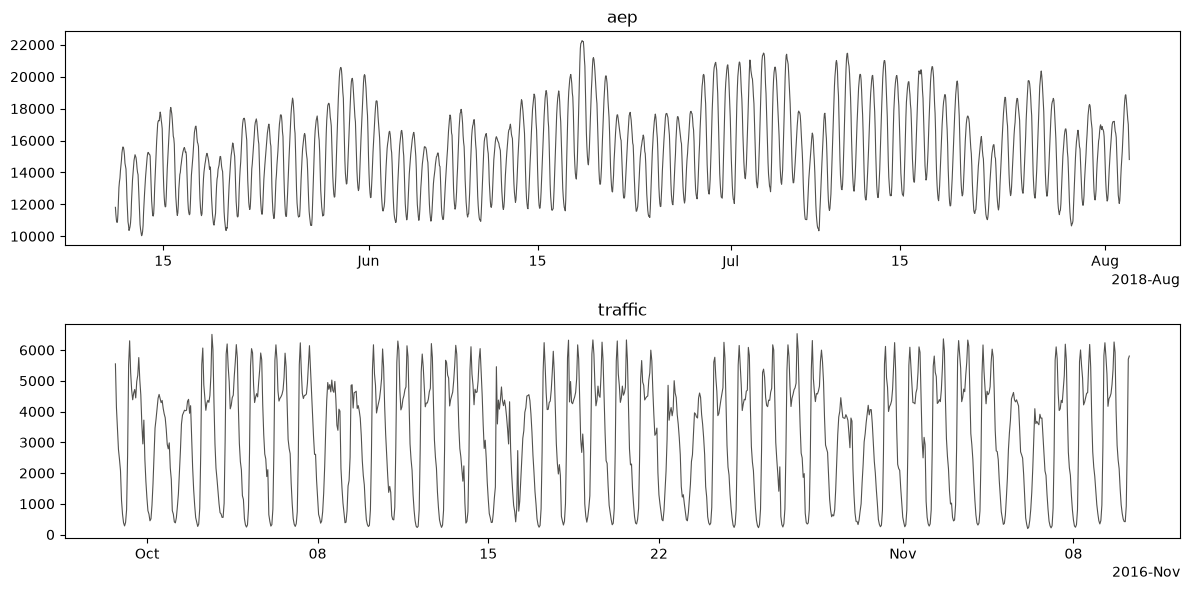

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6))
for ax, (uid, g) in zip(axes, df.groupby("unique_id")):
    ax.plot(g["ds"], g["y"], color=GRAY, lw=0.8)
    ax.set_title(uid)
fig.tight_layout()

На двухнедельном отрезке видна структура: суточный цикл (утренний и вечерний пик у трафика) и недельный (в выходные профиль другой).

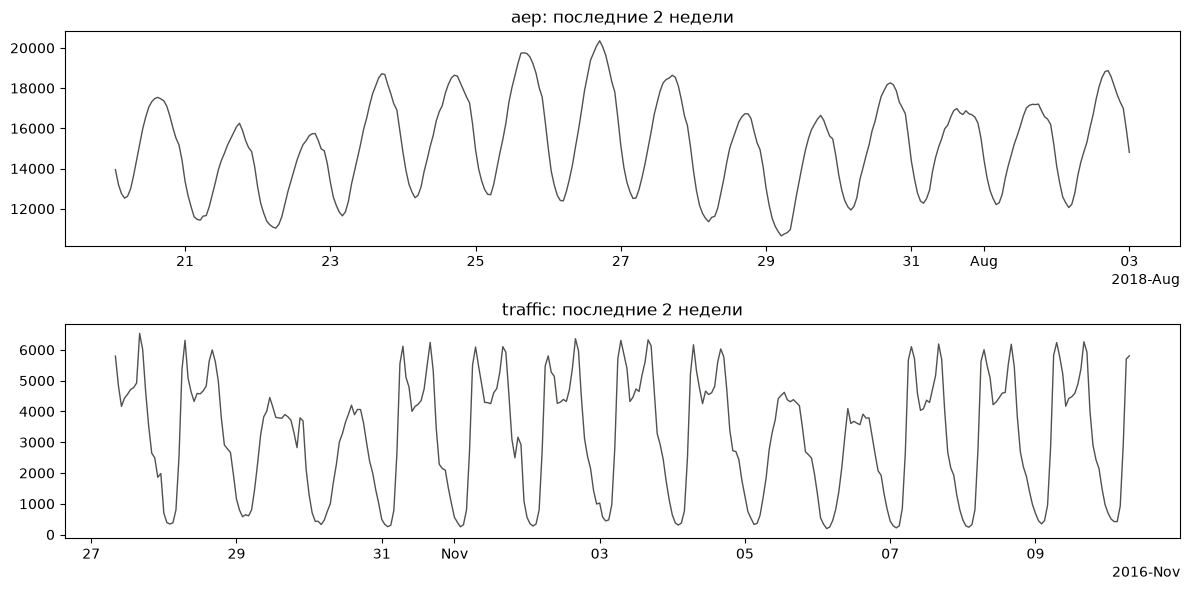

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6))
for ax, (uid, g) in zip(axes, df.groupby("unique_id")):
    g = g.tail(2 * 168)
    ax.plot(g["ds"], g["y"], color=GRAY, lw=1)
    ax.set_title(f"{uid}: последние 2 недели")
fig.tight_layout()

## 0. Зацепка

Отложим последнюю неделю трафика под тест и обучим `AutoTBATS`. Единственное, что мы сообщаем модели, — **сезонные периоды**. Всё остальное (Бокс-Кокс, тренд, ARMA, число гармоник) модель подбирает сама.

In [5]:
y = traffic["y"].to_numpy()
y_train, y_test = y[:-H], y[-H:]
ds_train, ds_test = traffic["ds"].iloc[:-H], traffic["ds"].iloc[-H:]

start = time.perf_counter()
auto = AutoTBATS(season_length=PERIODS).fit(y_train)
print(f"обучение: {time.perf_counter() - start:.0f} с")

fc = auto.predict(h=H, level=[95])

обучение: 37 с


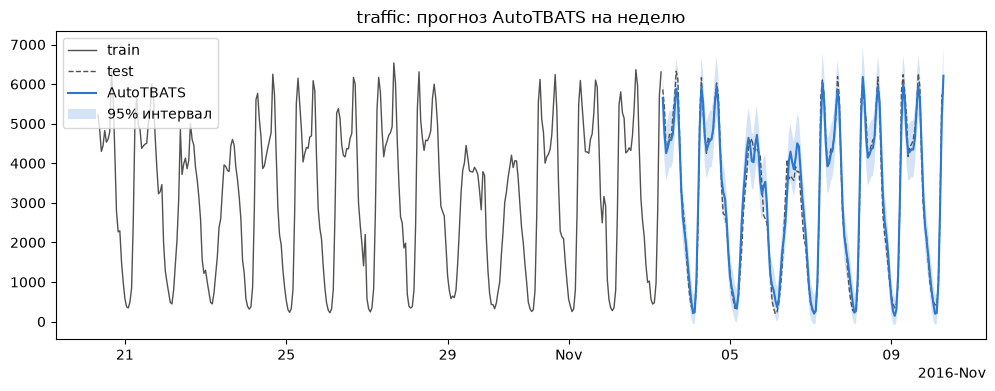

In [6]:
fig, ax = plt.subplots()
ax.plot(ds_train.iloc[-2 * H:], y_train[-2 * H:], color=GRAY, lw=1, label="train")
ax.plot(ds_test, y_test, color=GRAY, lw=1, ls="--", label="test")
ax.plot(ds_test, fc["mean"], lw=1.5, label="AutoTBATS")
ax.fill_between(ds_test, fc["lo-95"], fc["hi-95"], alpha=0.2, label="95% интервал")
ax.legend()
ax.set_title("traffic: прогноз AutoTBATS на неделю");

Модель хранит своё устройство в словаре `model_`: что выбрано и чему научились.

In [7]:
mod = auto.model_
print("структура:   ", mod["description"])
print("гармоники k: ", mod["k_vector"], "для периодов", PERIODS)
print("ARMA (p, q): ", (mod["p"], mod["q"]))
print("Бокс-Кокс λ: ", mod["BoxCox_lambda"])
print("матрицы:      w", mod["w_transpose"].shape, " F", mod["F"].shape, " g", mod["g"].shape, " состояния x", mod["x"].shape)

структура:    {'use_boxcox': True, 'use_trend': False, 'use_damped_trend': False, 'use_arma_errors': True}
гармоники k:  [ 5 30] для периодов [24, 168]
ARMA (p, q):  (2, 3)
Бокс-Кокс λ:  0.8267360806348593
матрицы:      w (1, 76)  F (76, 76)  g (76, 1)  состояния x (831, 76)


Как и ETS, TBATS умеет **раскладывать ряд на компоненты**: каждая компонента — это часть вектора состояний модели. В statsforecast готового метода для этого нет, поэтому напишем короткую функцию (почему она устроена именно так, станет понятно в разделе 2.3).

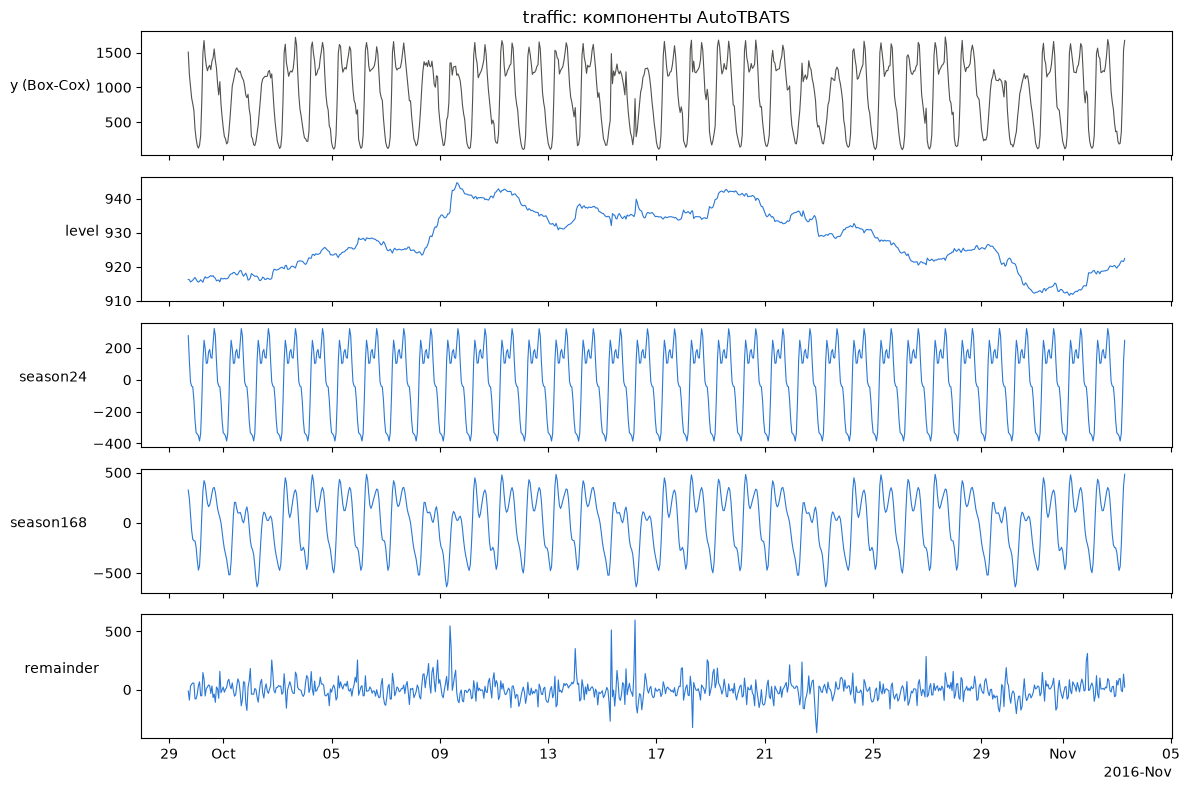

In [8]:
def tbats_components(mod, periods):
    """Вклад каждой компоненты в y_t (в шкале Бокса-Кокса).

    В уравнение наблюдения для y_t входят состояния x_{t-1}, поэтому берём состояния со сдвигом на шаг
    (для первой точки — начальные состояния seed_states).
    """
    x_prev = np.vstack([mod["seed_states"], mod["x"][:-1]])
    w = mod["w_transpose"][0]
    y_trans = (mod["fitted"] + mod["errors"]).ravel()  # ряд после преобразования Бокса-Кокса
    comps = {"y (Box-Cox)": y_trans, "level": x_prev[:, 0]}
    pos = 1
    if mod["description"]["use_trend"]:
        comps["trend"] = w[1] * x_prev[:, 1]  # φ·b_{t-1}
        pos = 2
    for m, k in zip(sorted(periods), mod["k_vector"]):
        comps[f"season{m}"] = x_prev[:, pos:pos + k].sum(axis=1)  # s_{t-1} = сумма первых k состояний блока
        pos += 2 * k
    comps["remainder"] = y_trans - sum(v for name, v in comps.items() if name != "y (Box-Cox)")  # = d_t
    return pd.DataFrame(comps)


def plot_components(comps, ds, title):
    fig, axes = plt.subplots(len(comps.columns), 1, figsize=(12, 1.6 * len(comps.columns)), sharex=True)
    for ax, col in zip(axes, comps.columns):
        ax.plot(ds, comps[col], lw=0.8, color=GRAY if col.startswith("y") else None)
        ax.set_ylabel(col, rotation=0, ha="right")
    axes[0].set_title(title)
    fig.tight_layout()


plot_components(tbats_components(mod, PERIODS), ds_train, "traffic: компоненты AutoTBATS")

Появляются вопросы:
- что за `level`, `season24`, `season168` и почему недельная сезонность «плывёт» во времени?
- откуда взялись числа гармоник `k` и почему их так мало по сравнению с периодом 168?
- почему модель решила обойтись без тренда?
- что за матрицы `w`, `F`, `g` и вектор состояний `x`?

Разберёмся по порядку.

## 1. Мотивация: сложная сезонность

Почасовые данные обычно содержат **несколько сезонностей**: сутки (24), неделя (168), иногда год (8766). Классический Holt-Winters для этого плохо подходит:

1. **Сезонность только одна.** Можно взять период 168 (неделя включает сутки), но тогда суточный профиль приходится учить заново для каждого из 7 дней.
2. **Каждая точка периода — отдельное состояние.** Для `m = 168` нужно 168 начальных сезонных состояний, для годовой сезонности дневного ряда — 365. Параметров много, оценивать их долго и неустойчиво.
3. **Нецелые периоды.** Год в неделях — 52.18, в днях — 365.25. Сезонный индекс `s_{t−m}` требует целого `m`.

Альтернативы из лекции:
- **гармоническая регрессия + ARIMA-ошибки**: сезонности задаются признаками Фурье $\sin(2\pi j t/m), \cos(2\pi j t/m)$, но коэффициенты постоянны во времени;
- **MSTL**: последовательно выделяем сезонности STL-разложением, остаток прогнозируем ETS/ARIMA.

TBATS (De Livera, Hyndman, Snyder, 2011) объединяет обе идеи: сезонность в виде гармоник Фурье, но **их коэффициенты — это состояния**, которые обновляются экспоненциальным сглаживанием и медленно меняются во времени.

Расшифровка названия: **T**rigonometric seasonality, **B**ox-Cox transformation, **A**RMA errors, **T**rend, **S**easonal components.

## 2. Формализация

### 2.1. Уравнения TBATS

$$
\begin{aligned}
y_t^{(\lambda)} &= \ell_{t-1} + \phi\, b_{t-1} + \sum_{i=1}^{T} s^{(i)}_{t-1} + d_t && \text{(наблюдение)}\\
\ell_t &= \ell_{t-1} + \phi\, b_{t-1} + \alpha\, d_t && \text{(уровень)}\\
b_t &= \phi\, b_{t-1} + \beta\, d_t && \text{(тренд с демпфированием } \phi)\\
d_t &= \sum_{i=1}^{p} \varphi_i\, d_{t-i} + \sum_{j=1}^{q} \theta_j\, \varepsilon_{t-j} + \varepsilon_t && \text{(ARMA}(p,q)\text{-ошибка)}
\end{aligned}
$$

где $y_t^{(\lambda)}$ — ряд после преобразования Бокса-Кокса $\frac{y^\lambda - 1}{\lambda}$ ($\log y$ при $\lambda = 0$), $T$ — число сезонностей, $\varepsilon_t \sim N(0, \sigma^2)$ — белый шум.

Каждая сезонность — сумма $k_i$ гармоник, каждая гармоника — пара состояний $(s_{j,t}, s^*_{j,t})$:

$$
\begin{aligned}
s^{(i)}_t &= \sum_{j=1}^{k_i} s^{(i)}_{j,t}, \qquad \omega^{(i)}_j = \frac{2\pi j}{m_i}\\
s^{(i)}_{j,t} &= \phantom{-}s^{(i)}_{j,t-1}\cos\omega^{(i)}_j + s^{*(i)}_{j,t-1}\sin\omega^{(i)}_j + \gamma^{(i)}_1 d_t\\
s^{*(i)}_{j,t} &= -s^{(i)}_{j,t-1}\sin\omega^{(i)}_j + s^{*(i)}_{j,t-1}\cos\omega^{(i)}_j + \gamma^{(i)}_2 d_t
\end{aligned}
$$

Это **модель инноваций** (как ETS): во всех уравнениях один и тот же источник случайности $d_t$, а сглаживающие коэффициенты $\alpha, \beta, \gamma$ задают, какая доля «сюрприза» попадает в каждое состояние.

> **Поправки к слайду 14 лекции.** (1) В ARMA-части должно быть $\varphi_i\, d_{t-i}$, а не $d_{t-1}$. (2) На слайде (и в статье) одна буква $\phi$ обозначает и демпфирование тренда, и AR-коэффициенты. Здесь они разведены: $\phi$ — демпфирование, $\varphi_i$ — AR. (3) В уравнении наблюдения у TBATS стоит $s^{(i)}_{t-1}$: тригонометрическое состояние за один шаг «поворачивается» само. Сдвиг $s_{t-m_i}$ — это запись BATS.

Частные случаи: без тренда — $b_t \equiv 0$; без демпфирования — $\phi = 1$; без ARMA — $d_t = \varepsilon_t$; без Бокса-Кокса — $\lambda = 1$.

### 2.2. Дискретная (BATS) vs тригонометрическая (TBATS) сезонность

В **BATS** сезонность устроена как в Holt-Winters:
$$ s^{(i)}_t = s^{(i)}_{t-m_i} + \gamma_i\, d_t, $$
т.е. для каждого периода хранится $m_i$ состояний — значение сезонности в каждой «фазе». В **TBATS** — $2k_i$ состояний (по паре на гармонику), и обычно $k_i \ll m_i / 2$.

В statsforecast реализован только TBATS (BATS есть в sktime через пакет `tbats`). Поэтому разница показана на уровне устройства модели. Сначала сравним размер вектора состояний для подобранной выше модели:

In [9]:
states = pd.DataFrame(
    {"BATS: m состояний": PERIODS, "k (подобрано)": mod["k_vector"], "TBATS: 2k состояний": 2 * mod["k_vector"]},
    index=pd.Index(PERIODS, name="период m"),
)
states.loc["итого"] = states.sum()
states

,BATS: m состояний,k (подобрано),TBATS: 2k состояний
период m,,,
24,24,5,10
168,168,30,60
итого,192,35,70


**Пара состояний — это поворот.** Уравнения гармоники в матричном виде:
$$
\begin{pmatrix} s_{j,t} \\ s^*_{j,t} \end{pmatrix} =
\underbrace{\begin{pmatrix} \cos\omega_j & \sin\omega_j \\ -\sin\omega_j & \cos\omega_j \end{pmatrix}}_{\text{поворот на угол } \omega_j}
\begin{pmatrix} s_{j,t-1} \\ s^*_{j,t-1} \end{pmatrix} + \begin{pmatrix} \gamma_1 \\ \gamma_2 \end{pmatrix} d_t
$$
За $m$ шагов точка совершает полный оборот ($m\omega_1 = 2\pi$), а $s_{j,t}$ — её проекция, т.е. синусоида с периодом $m/j$. При $\gamma = 0$ амплитуда и фаза фиксированы (это ровно гармоническая регрессия). При $\gamma > 0$ ошибки «подталкивают» точку, и форма сезонности медленно меняется.

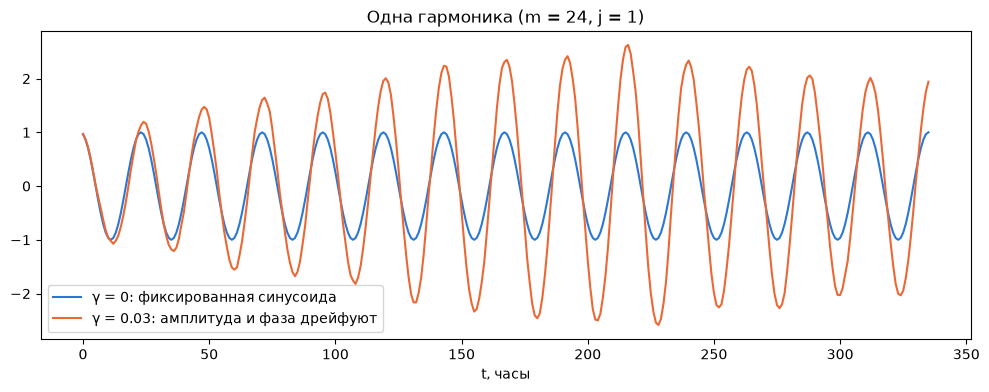

In [10]:
def simulate_harmonic(m, j, gamma, n, seed=0):
    rng = np.random.default_rng(seed)
    w = 2 * np.pi * j / m
    R = np.array([[np.cos(w), np.sin(w)], [-np.sin(w), np.cos(w)]])
    state, out = np.array([1.0, 0.0]), []
    for d in rng.normal(size=n):
        state = R @ state + gamma * d
        out.append(state[0])
    return np.array(out)


t = np.arange(24 * 14)
fig, ax = plt.subplots()
ax.plot(t, simulate_harmonic(24, 1, 0.0, len(t)), label="γ = 0: фиксированная синусоида")
ax.plot(t, simulate_harmonic(24, 1, 0.03, len(t)), label="γ = 0.03: амплитуда и фаза дрейфуют")
ax.set_xlabel("t, часы")
ax.legend()
ax.set_title("Одна гармоника (m = 24, j = 1)");

**Полный набор гармоник ⇔ дамми.** Любая периодическая последовательность с периодом $m$ точно раскладывается в сумму $m/2$ гармоник (дискретное преобразование Фурье). Проверим: $m$ сезонных дамми и константа + все гармоники ($\cos$ для $j = 1..m/2$, $\sin$ для $j = 1..m/2-1$; $\sin(\pi t) \equiv 0$) порождают одно и то же пространство — ранг объединённой матрицы равен $m$.

In [11]:
def fourier(t, m, k):
    """Признаки Фурье: cos и sin для гармоник j = 1..k."""
    w = 2 * np.pi * np.outer(t, np.arange(1, k + 1)) / m
    return np.hstack([np.cos(w), np.sin(w)])


m = 24
t = np.arange(10 * m)
dummies = np.eye(m)[t % m]
full_fourier = np.column_stack([np.ones(len(t)), fourier(t, m, m // 2)[:, :-1]])  # убираем sin(πt) ≡ 0

print("ранг дамми:         ", np.linalg.matrix_rank(dummies))
print("ранг Фурье (k = m/2):", np.linalg.matrix_rank(full_fourier))
print("ранг объединения:   ", np.linalg.matrix_rank(np.hstack([dummies, full_fourier])))

ранг дамми:          24
ранг Фурье (k = m/2): 24
ранг объединения:    24


Значит, **BATS ≈ TBATS с полным набором гармоник** (с точностью до того, как сглаживание распределяет ошибку по состояниям). TBATS просто **обрезает спектр**: оставляет $k$ первых гармоник, потому что реальные сезонные профили гладкие и описываются несколькими гармониками.

Посмотрим на средний недельный профиль трафика (168 значений) и его приближение $k$ гармониками:

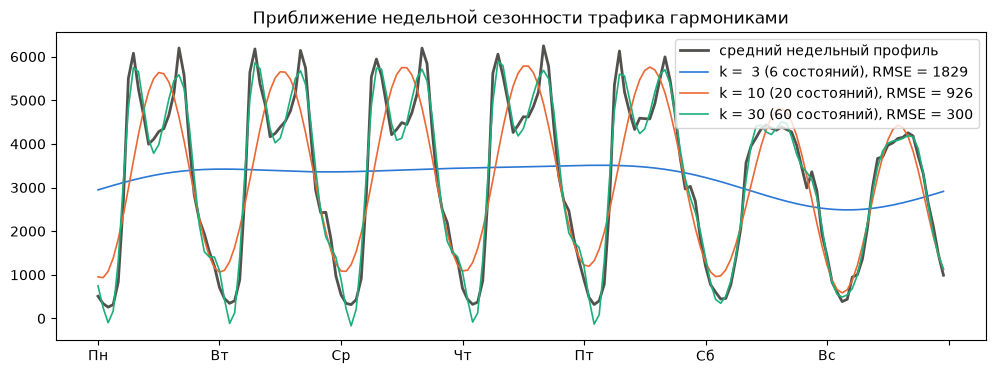

In [12]:
hour_of_week = traffic["ds"].dt.dayofweek * 24 + traffic["ds"].dt.hour
profile = traffic.groupby(hour_of_week)["y"].mean().to_numpy()
t = np.arange(168)

fig, ax = plt.subplots()
ax.plot(t, profile, color=GRAY, lw=2, label="средний недельный профиль")
for k in [3, 10, 30]:
    X = np.column_stack([np.ones(168), fourier(t, 168, k)])
    approx = X @ np.linalg.lstsq(X, profile, rcond=None)[0]
    rmse_k = np.sqrt(np.mean((profile - approx) ** 2))
    ax.plot(t, approx, lw=1.2, label=f"k = {k:>2} ({2 * k} состояний), RMSE = {rmse_k:.0f}")
ax.set_xticks(np.arange(0, 169, 24), ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс", ""])
ax.legend()
ax.set_title("Приближение недельной сезонности трафика гармониками");

Уже при $k = 30$ (60 состояний вместо 168) профиль почти неотличим от исходного. Отсюда три преимущества тригонометрической записи:
- **меньше параметров** для длинных периодов;
- **нецелые периоды**: $\omega_j = 2\pi j / m$ имеет смысл при любом $m$, например 52.18. В statsforecast, правда, принимаются только целые `season_length` (`30.44` падает с ошибкой);
- **гладкость** сезонного профиля задаётся одним числом $k$.

### 2.3. Запись в пространстве состояний

Все уравнения 2.1 собираются в линейную модель пространства состояний:

$$
\begin{aligned}
y_t^{(\lambda)} &= w^\top x_{t-1} + \varepsilon_t && \text{(наблюдение)}\\
x_t &= F\, x_{t-1} + g\, \varepsilon_t && \text{(переход)}
\end{aligned}
$$

- $x_t = (\ell_t,\ b_t,\ s^{(1)}_{1..k_1,t},\ s^{*(1)}_{1..k_1,t},\ s^{(2)}_{\dots},\ d_t, \dots, d_{t-p+1},\ \varepsilon_t, \dots, \varepsilon_{t-q+1})$ — вектор состояний;
- $w$ — какие состояния и с какими весами попадают в прогноз: $1$ у уровня, $\phi$ у тренда, $1$ у каждого $s_{j}$ (у $s^*_j$ — 0), $\varphi_i$ и $\theta_j$ у ARMA-части;
- $F$ — как состояния переходят во времени: блоки поворота для гармоник, $\phi$ для тренда, AR/MA-коэффициенты;
- $g$ — сглаживающие коэффициенты: $\alpha$, $\beta$, $\gamma_1^{(i)}, \gamma_2^{(i)}$.

Именно поэтому функция `tbats_components` выше берёт уровень из первой координаты состояния, а сезонность — суммой первых $k_i$ состояний блока: это ровно те координаты, где у $w$ стоят единицы. Состояния берутся за $t-1$, потому что именно они входят в уравнение наблюдения для $y_t$. Тогда остаток $y^{(\lambda)}_t - \ell_{t-1} - \phi b_{t-1} - \sum_i s^{(i)}_{t-1}$ — это в точности ARMA-ошибка $d_t$.

Подпишем координаты вектора состояний и посмотрим на $w$ и $g$ обученной модели:

In [13]:
def state_names(mod, periods):
    names = ["level"]
    if mod["description"]["use_trend"]:
        names.append("slope")
    for m, k in zip(sorted(periods), mod["k_vector"]):
        names += [f"s{m}_{j}" for j in range(1, k + 1)] + [f"s*{m}_{j}" for j in range(1, k + 1)]
    names += [f"d_t-{i}" if i else "d_t" for i in range(mod["p"])]
    names += [f"eps_t-{j}" if j else "eps_t" for j in range(mod["q"])]
    return names


names = state_names(mod, PERIODS)
wg = pd.DataFrame({"w": mod["w_transpose"][0], "g": mod["g"][:, 0]}, index=names)
# уровень, первые гармоники каждой сезонности и ARMA-часть (остальные гармоники устроены так же)
wg[~wg.index.str.match(r"s\*?\d+_([2-9]|\d{2})$")]

,w,g
level,1.000000,0.006929
s24_1,1.000000,0.000015
s*24_1,0.000000,-0.000346
s168_1,1.000000,0.000117
s*168_1,0.000000,0.000314
d_t,0.881031,1.000000
d_t-1,-0.259027,0.000000
eps_t,-0.591302,1.000000
eps_t-1,-0.110322,0.000000
eps_t-2,0.268362,0.000000


Матрица перехода $F$ целиком: блочная структура видна сразу. Внутри сезонных блоков — повороты (диагонали $\cos\omega_j$ и $\pm\sin\omega_j$), в правом нижнем углу — ARMA-часть. Нижние строки и правые столбцы заполнены, потому что $d_t$ влияет на все состояния (через $g$).

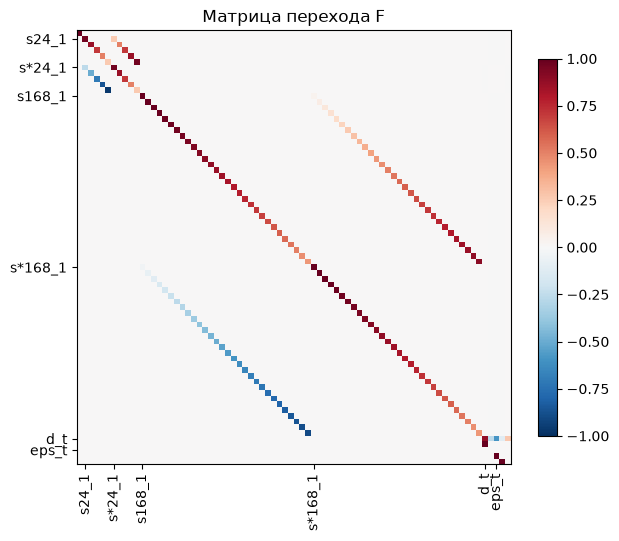

In [14]:
F = mod["F"]
lim = np.abs(F).max()

fig, ax = plt.subplots(figsize=(7, 7))
im = ax.imshow(F, cmap="RdBu_r", vmin=-lim, vmax=lim)
starts = [i for i, n in enumerate(names) if n.endswith("_1") or n in ("d_t", "eps_t")]
ax.set_xticks(starts, [names[i] for i in starts], rotation=90)
ax.set_yticks(starts, [names[i] for i in starts])
fig.colorbar(im, shrink=0.7)
ax.set_title("Матрица перехода F");

**Как получаются прогнозы.** Будущие $\varepsilon$ неизвестны (их матожидание 0), поэтому прогноз — это многократное применение $F$ к последнему состоянию: $\hat y_{T+h}^{(\lambda)} = w^\top F^{h-1} x_T$. Затем выполняется обратное преобразование Бокса-Кокса. Дисперсия ошибки растёт с горизонтом, $\sigma^2_h = \sigma^2 \bigl(1 + \sum_{j=1}^{h-1} c_j^2\bigr)$, где $c_j = w^\top F^{j-1} g$. После обратного Бокса-Кокса интервалы становятся **несимметричными** (на графике в зацепке это видно).

### 2.4. Что обучается, а что выбирается

Обучаемые параметры оцениваются максимизацией правдоподобия (Nelder–Mead) при фиксированной структуре. Гиперпараметры (структура) перебираются, и лучший вариант выбирается по AIC (раздел 3).

| | Что это | Где лежит в `model_` |
|---|---|---|
| **Обучаемые параметры** | | |
| $\lambda$ | параметр Бокса-Кокса | `BoxCox_lambda` |
| $\alpha$, $\beta$ | сглаживание уровня и тренда | `g[0]`, `g[1]` |
| $\phi$ | демпфирование тренда | `w_transpose[0, 1]` |
| $\gamma^{(i)}_1, \gamma^{(i)}_2$ | сглаживание $i$-й сезонности (одна пара на период) | блоки `g` |
| $\varphi_i$, $\theta_j$ | ARMA-коэффициенты | хвост `w_transpose` |
| $x_0$ | начальные состояния | `seed_states` |
| $\sigma^2$ | дисперсия шума | `sigma2` |
| **Гиперпараметры** | | |
| $m_i$ | сезонные периоды | задаёт пользователь (`season_length`) |
| $k_i$ | число гармоник | `k_vector` |
| $p, q$ | порядки ARMA | `p`, `q` |
| вкл/выкл | Бокс-Кокс, тренд, демпфирование, ARMA | `description` |

Вытащим параметры из матриц $g$ и $w$:

In [15]:
def tbats_params(mod, periods):
    w, g = mod["w_transpose"][0], mod["g"][:, 0]
    desc = mod["description"]
    params = {"lambda": mod["BoxCox_lambda"], "alpha": g[0]}
    pos = 1
    if desc["use_trend"]:
        params |= {"beta": g[1], "phi": w[1]}
        pos = 2
    for m, k in zip(sorted(periods), mod["k_vector"]):
        params |= {f"gamma1_{m}": g[pos], f"gamma2_{m}": g[pos + k]}
        pos += 2 * k
    params |= {f"ar{i + 1}": c for i, c in enumerate(w[pos:pos + mod["p"]])}
    params |= {f"ma{j + 1}": c for j, c in enumerate(w[pos + mod["p"]:pos + mod["p"] + mod["q"]])}
    params["sigma2"] = mod["sigma2"]
    return pd.Series(params)


tbats_params(mod, PERIODS).to_frame("traffic (train)").T

,lambda,alpha,gamma1_24,gamma2_24,gamma1_168,gamma2_168,ar1,ar2,ma1,ma2,ma3,sigma2
traffic (train),0.826736,0.006929,0.000015,-0.000346,0.000117,0.000314,0.881031,-0.259027,-0.591302,-0.110322,0.268362,6318.01435


Сглаживающие коэффициенты сезонностей $\gamma$ маленькие (порядка $10^{-4}$): сезонный профиль меняется медленно, но всё-таки меняется. Это и видно на графике компонент.

## 3. Как `AutoTBATS` выбирает модель

Пользователь задаёт только `season_length`. Дальше `statsforecast` (функция `tbats_selection` в `tbats.py`) выполняет:

1. **Число гармоник $k_i$** — отдельно и *до* подбора всей модели, по каждому периоду от меньшего к большему:
   - ряд детрендируется скользящим средним окна $2m$;
   - на остаток регрессируются признаки Фурье с $k = 1, 2, \dots$ (МНК), для каждого $k$ считается AIC регрессии;
   - $k$ растёт, пока AIC улучшается; поиск останавливается после 2 шагов без улучшения;
   - найденная гармоническая часть вычитается из ряда, и процедура повторяется для следующего периода.

   В статье De Livera и в R-пакете `forecast` $k$ выбирается по AIC **полной** модели TBATS. Это точнее, но гораздо дольше.
2. **Структура** — перебор Бокс-Кокс {вкл, выкл} × тренд {демпфированный, линейный, нет}, всего до 6 вариантов. Каждый вариант обучается по MLE.
3. **ARMA-ошибки** — внутри каждого варианта: сначала модель без ARMA, затем `auto_arima` по её остаткам подбирает $(p, q)$, и модель переобучается с ARMA. Вариант с ARMA сохраняется, только если его AIC **строго** лучше.
4. **$\lambda$** стартует с оценки Guerrero и дальше оптимизируется вместе с остальными параметрами в границах `[bc_lower_bound, bc_upper_bound] = [0, 1]`. AIC с разными $\lambda$ сравнимы: в правдоподобие входит якобиан преобразования.
5. Побеждает вариант с минимальным AIC.

Экзогенные признаки `X` модель **игнорирует** (`fit(y, X=None)`: «X — Ignored»), даже если они переданы в `StatsForecast.forecast(..., X_df=...)`.

Повторим шаг 1 на трафике и посмотрим на кривые AIC:

k_vector модели: [ 5 30]


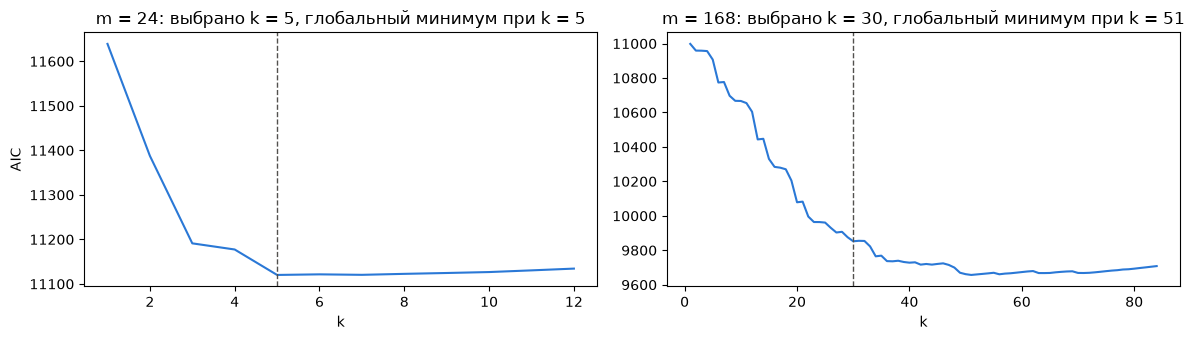

In [16]:
def harmonics_aic(y, m):
    """AIC регрессии детрендированного ряда на k = 1..m/2 гармоник, как в statsforecast."""
    z = y - pd.Series(y).rolling(2 * m, min_periods=1).mean().to_numpy()
    t = np.arange(len(y))
    aic, fits = [], []
    for k in range(1, m // 2 + 1):
        X = fourier(t, m, k)
        coef = np.linalg.lstsq(X, z, rcond=None)[0]
        rss = np.sum((z - X @ coef) ** 2)
        aic.append(len(z) * np.log(rss / len(z)) + 2 * X.shape[1])
        fits.append(X @ coef)
    return np.array(aic), fits


def early_stop_k(aic, tol=2):
    best, without_improv = 0, 0
    for i in range(1, len(aic)):
        if aic[i] < aic[best]:
            best, without_improv = i, 0
        else:
            without_improv += 1
            if without_improv >= tol:
                break
    return best + 1


z = y_train.copy()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, m in zip(axes, PERIODS):
    aic, fits = harmonics_aic(z, m)
    k_sel = early_stop_k(aic)
    z = z - fits[k_sel - 1]  # вычитаем найденную гармоническую часть перед следующим периодом
    ax.plot(np.arange(1, len(aic) + 1), aic, lw=1.5)
    ax.axvline(k_sel, color=GRAY, ls="--", lw=1)
    ax.set_title(f"m = {m}: выбрано k = {k_sel}, глобальный минимум при k = {aic.argmin() + 1}")
    ax.set_xlabel("k")
axes[0].set_ylabel("AIC")
fig.tight_layout()
print("k_vector модели:", mod["k_vector"])

Ранняя остановка не обязательно находит глобальный минимум AIC: это быстрая эвристика, а не полный перебор.

**ARMA-ошибки.** Если после выделения уровня и сезонностей в остатках осталась автокорреляция, её забирает ARMA-часть. Сравним ACF остатков подобранной модели и модели с той же структурой, но без ARMA:

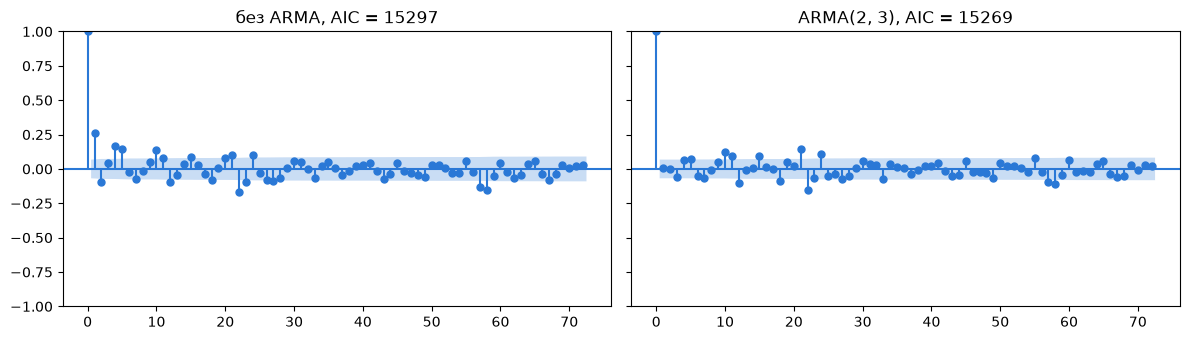

In [17]:
desc = mod["description"]
no_arma = TBATS(
    PERIODS, use_boxcox=desc["use_boxcox"], use_trend=desc["use_trend"],
    use_damped_trend=desc["use_damped_trend"], use_arma_errors=False,
).fit(y_train)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
plot_acf(no_arma.model_["errors"].ravel(), lags=72, ax=axes[0], title=f"без ARMA, AIC = {no_arma.model_['aic']:.0f}")
plot_acf(mod["errors"].ravel(), lags=72, ax=axes[1], title=f"ARMA({mod['p']}, {mod['q']}), AIC = {mod['aic']:.0f}")
fig.tight_layout()

## 4. Применение

Дальше работаем с обоими рядами сразу. `StatsForecast` обучает все модели на каждом `unique_id`.

> `n_jobs=-1` распараллеливает обучение по рядам. В песочнице, где собирался ноутбук, многопроцессность запрещена, поэтому здесь `n_jobs=1`.

### 4.1. Компоненты: TBATS vs MSTL

Обучим `AutoTBATS` и `MSTL` (остаток после сезонностей прогнозирует `AutoETS` без сезонности) на полных рядах и сравним разложения.

In [18]:
sf_full = StatsForecast(
    models=[AutoTBATS(PERIODS), MSTL(PERIODS, trend_forecaster=AutoETS(model="ZZN"))],
    freq="h", n_jobs=1,
)
start = time.perf_counter()
sf_full.fit(df)
print(f"обучение: {time.perf_counter() - start:.0f} с")

fitted = {uid: {m.alias: m for m in row} for uid, row in zip(sf_full.uids, sf_full.fitted_)}

обучение: 60 с


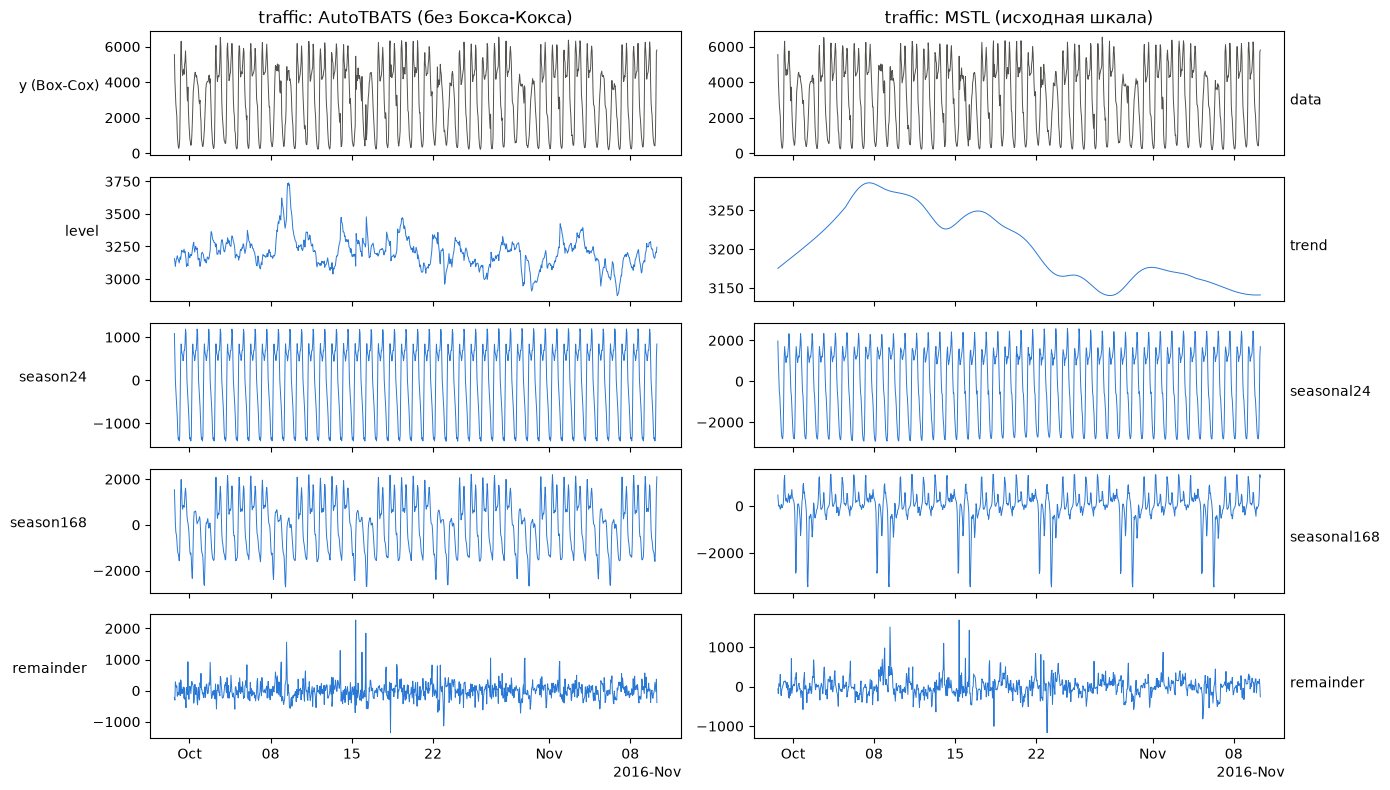

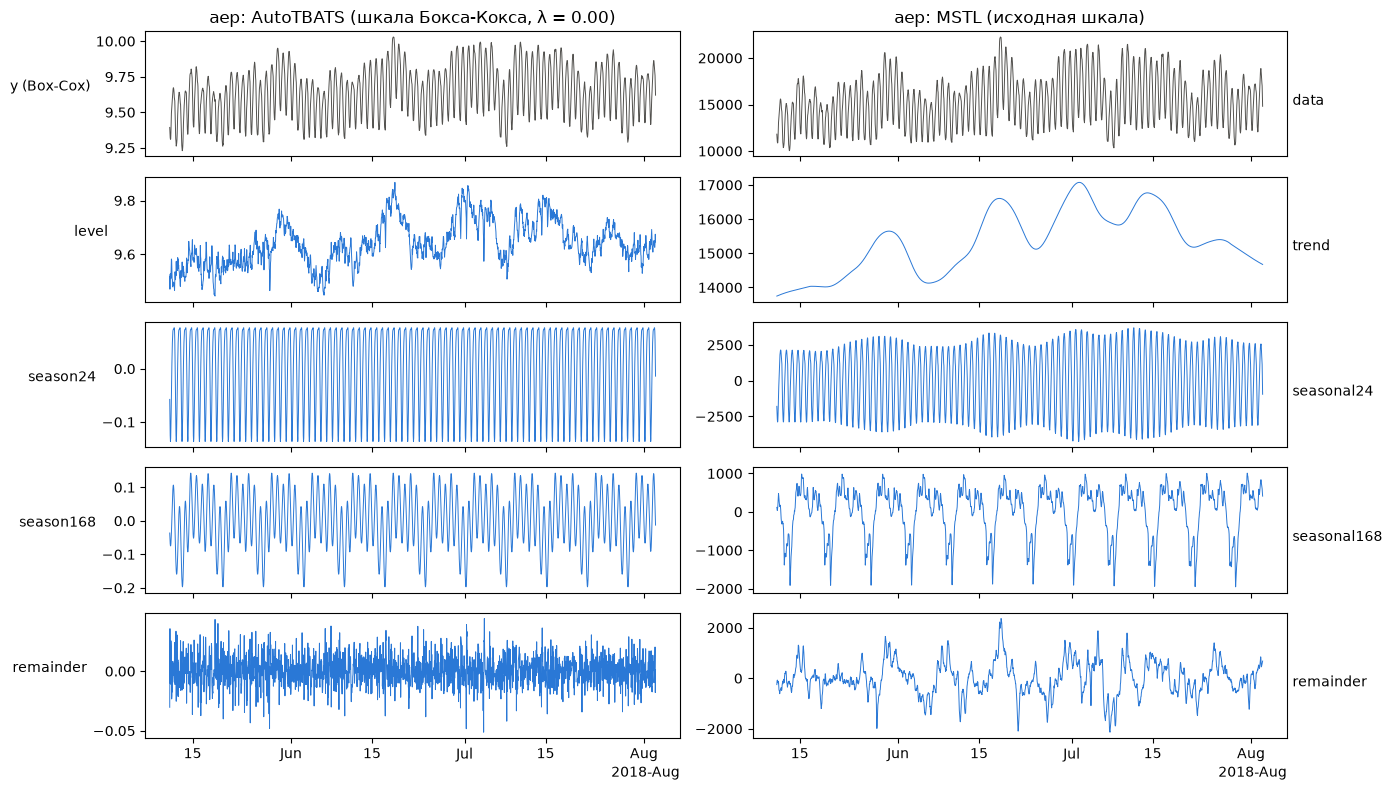

In [19]:
for uid in ["traffic", "aep"]:
    ds = df.loc[df["unique_id"] == uid, "ds"]
    tbats_mod = fitted[uid]["AutoTBATS"].model_
    tbats_comps = tbats_components(tbats_mod, PERIODS)
    mstl_comps = fitted[uid]["MSTL"].model_

    rows = ["data", "trend", "seasonal24", "seasonal168", "remainder"]
    tbats_cols = ["y (Box-Cox)", "level", "season24", "season168", "remainder"]
    fig, axes = plt.subplots(len(rows), 2, figsize=(14, 8), sharex=True)
    for r, (mstl_col, tbats_col) in enumerate(zip(rows, tbats_cols)):
        axes[r, 0].plot(ds, tbats_comps[tbats_col], lw=0.7, color=GRAY if r == 0 else None)
        axes[r, 1].plot(ds, mstl_comps[mstl_col], lw=0.7, color=GRAY if r == 0 else None)
        axes[r, 0].set_ylabel(tbats_col, rotation=0, ha="right")
        axes[r, 1].set_ylabel(mstl_col, rotation=0, ha="left")
        axes[r, 1].yaxis.set_label_position("right")
    lam = tbats_mod["BoxCox_lambda"]
    lam_text = "без Бокса-Кокса" if lam is None else f"шкала Бокса-Кокса, λ = {lam:.2f}"
    axes[0, 0].set_title(f"{uid}: AutoTBATS ({lam_text})")
    axes[0, 1].set_title(f"{uid}: MSTL (исходная шкала)")
    fig.tight_layout()

Что видно:
- Обе модели выделяют похожие суточную и недельную сезонности. Если TBATS выбрал Бокса-Кокса, его компоненты живут в преобразованной шкале и аддитивны только в ней. У AEP $\lambda \approx 0$, т.е. это логарифм: постоянная амплитуда `season24` в лог-шкале означает колебания, пропорциональные уровню, в исходной. MSTL ту же картину передаёт меняющейся амплитудой `seasonal24` в МВт.
- Уровень TBATS — сглаженный, но «живой» (это состояние, а не скользящее среднее): он забирает и часть нерегулярных колебаний. Остаток TBATS — это ARMA-ошибка $d_t$.
- У MSTL сезонность тоже может меняться во времени (параметр `seasonal` в STL), но разложение делается *до* прогноза, независимо от модели остатка. В TBATS все компоненты оцениваются **совместно** в одной модели правдоподобия.

### 4.2. Варианты модели: ARMA, тренд, Бокс-Кокс

Зафиксируем структуру вручную через `TBATS` и посмотрим, как каждая «ручка» влияет на AIC (качество подгонки на всём ряде) и на ошибку прогноза на кросс-валидации (3 окна по неделе).

Базовый вариант — без тренда, без ARMA, без Бокса-Кокса; каждый следующий меняет одну ручку.

In [20]:
variants = [
    TBATS(PERIODS, use_boxcox=False, use_trend=False, use_arma_errors=False, alias="base"),
    TBATS(PERIODS, use_boxcox=False, use_trend=False, use_arma_errors=True, alias="+ARMA"),
    TBATS(PERIODS, use_boxcox=False, use_trend=True, use_damped_trend=False, alias="+trend"),
    TBATS(PERIODS, use_boxcox=False, use_trend=True, use_damped_trend=True, alias="+damped trend"),
    TBATS(PERIODS, use_boxcox=True, use_trend=False, use_arma_errors=False, alias="+Box-Cox"),
]
aliases = [v.alias for v in variants]

sf_var = StatsForecast(models=variants, freq="h", n_jobs=1)
start = time.perf_counter()
sf_var.fit(df)
cv_var = sf_var.cross_validation(df=df, h=H, n_windows=3, step_size=H)
print(f"обучение + CV: {time.perf_counter() - start:.0f} с")

обучение + CV: 38 с


In [21]:
def arma_label(m):
    return f"ARMA({m['p']}, {m['q']})" if m["description"]["use_arma_errors"] else "нет"


var_models = {uid: {m.alias: m.model_ for m in row} for uid, row in zip(sf_var.uids, sf_var.fitted_)}
cv_mae = evaluate(cv_var.drop(columns="cutoff"), metrics=[mae]).set_index("unique_id")[aliases].T

pd.concat({
    "AIC": pd.DataFrame({uid: {a: m["aic"] for a, m in ms.items()} for uid, ms in var_models.items()}),
    "MAE на CV": cv_mae,
    "λ": pd.DataFrame({uid: {a: m["BoxCox_lambda"] for a, m in ms.items()} for uid, ms in var_models.items()}),
    "ARMA": pd.DataFrame({uid: {a: arma_label(m) for a, m in ms.items()} for uid, ms in var_models.items()}),
}, axis=1).round(2)

AIC           MAE на CV            λ                ARMA  \
                    aep   traffic       aep traffic  aep traffic         aep   
base           36543.61  18359.73    829.63  276.16  NaN     NaN         нет   
+ARMA          36476.26  18359.73    840.84  274.86  NaN     NaN  ARMA(2, 2)   
+trend         36698.11  18411.88    857.56  376.56  NaN     NaN         нет   
+damped trend  36633.66  18369.31    991.02  315.67  NaN     NaN         нет   
+Box-Cox       36433.04  18364.58    822.32  267.83  0.0     1.0         нет   

                       
              traffic  
base              нет  
+ARMA             нет  
+trend            нет  
+damped trend     нет  
+Box-Cox          нет

На что смотреть:
- **ARMA**: «нет» значит, что `auto_arima` нашёл порядки, но модель с ARMA не улучшила AIC, и она отброшена. Тогда результат совпадает с `base`.
- **Тренд** на недельном горизонте обычно мешает: линейный тренд экстраполирует последние колебания уровня. Демпфирование смягчает эффект.
- **Бокс-Кокс** полезен, когда амплитуда сезонности растёт вместе с уровнем. $\lambda \approx 0$ означает логарифм; $\lambda$ на верхней границе 1 — преобразование фактически не нужно (отличие от `base` тогда только в пути оптимизации).
- Лучший AIC не гарантирует лучший прогноз: AIC меряет подгонку на истории с одним шагом вперёд, а CV — ошибку на горизонте до 168 шагов.

ACF остатков для AEP с ARMA и без:

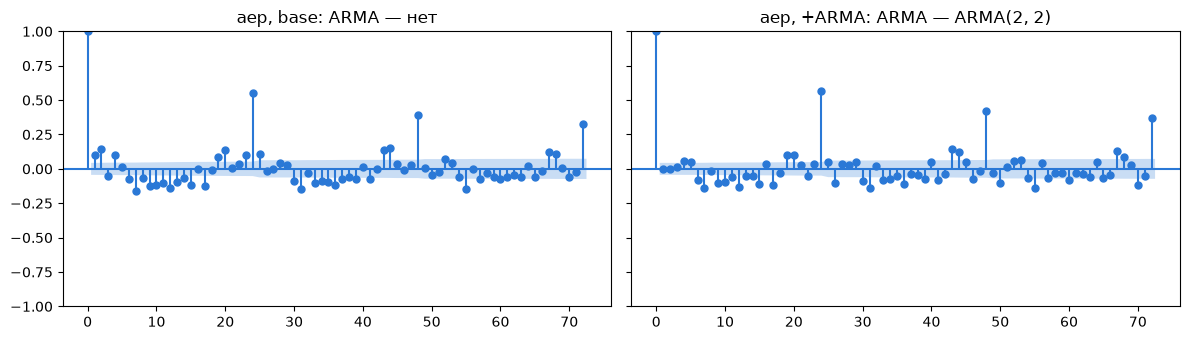

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, alias in zip(axes, ["base", "+ARMA"]):
    m_ = var_models["aep"][alias]
    plot_acf(m_["errors"].ravel(), lags=72, ax=ax, title=f"aep, {alias}: ARMA — {arma_label(m_)}")
fig.tight_layout()

ARMA убирает автокорреляцию на коротких лагах, но пики на лагах 24, 48, 72 остаются. Это недоучтённая суточная сезонность: эвристика выбрала для периода 24 всего $k = 3$ гармоники (см. таблицу в 4.4), и острый суточный профиль потребления ими не описывается. ARMA($p$, $q$) с малыми порядками сезонную автокорреляцию не исправит. Так проявляется цена быстрого подбора $k$ из раздела 3.

### 4.3. AutoTBATS vs MSTL vs SeasonalNaive

Честное сравнение — rolling-кросс-валидация: 3 отсечки, на каждой прогноз на неделю вперёд.
- **SeasonalNaive(168)** — повторить прошлую неделю. Минимальный бейзлайн для рядов с недельной сезонностью.
- **MSTL** — разложение на две сезонности + `AutoETS` на остатке.
- **AutoTBATS** — полный автоподбор.

In [23]:
final_models = [
    AutoTBATS(PERIODS),
    MSTL(PERIODS, trend_forecaster=AutoETS(model="ZZN")),
    SeasonalNaive(season_length=168),
]
sf_cv = StatsForecast(models=final_models, freq="h", n_jobs=1)
start = time.perf_counter()
cv = sf_cv.cross_validation(df=df, h=H, n_windows=3, step_size=H)
print(f"CV: {time.perf_counter() - start:.0f} с")

model_names = [m.alias for m in final_models]
evaluate(cv.drop(columns="cutoff"), metrics=[mae, rmse]).set_index(["unique_id", "metric"])[model_names].round(1)

CV: 111 с


,,AutoTBATS,MSTL,SeasonalNaive
unique_id,metric,,,
aep,mae,889.4,844.5,1275.7
traffic,mae,264.4,247.5,280.8
aep,rmse,1126.5,1071.5,1691.5
traffic,rmse,356.4,346.9,432.4


Время обучения одной модели на полном ряде:

In [24]:
fit_time = {}
for uid, g in df.groupby("unique_id"):
    y_full = g["y"].to_numpy()
    for model in final_models:
        start = time.perf_counter()
        model.fit(y_full)
        fit_time[(uid, model.alias)] = time.perf_counter() - start
pd.Series(fit_time).unstack().round(2).rename_axis(index="ряд", columns="модель, с")

"модель, с",AutoTBATS,MSTL,SeasonalNaive
ряд,,,
aep,12.62,0.31,0.0
traffic,46.69,0.14,0.0


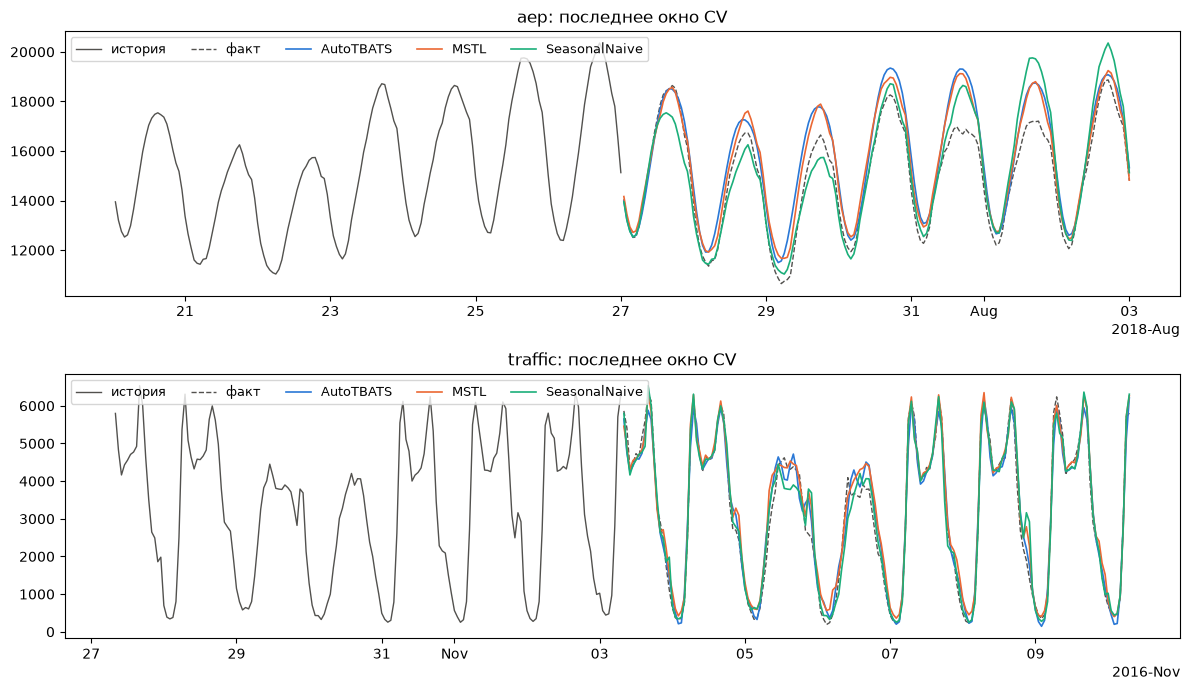

In [25]:
last_cutoff = cv.groupby("unique_id")["cutoff"].transform("max")
last = cv[cv["cutoff"] == last_cutoff]

fig, axes = plt.subplots(2, 1, figsize=(12, 7))
for ax, (uid, g) in zip(axes, last.groupby("unique_id")):
    history = df[(df["unique_id"] == uid) & (df["ds"] <= g["cutoff"].iloc[0])].tail(H)
    ax.plot(history["ds"], history["y"], color=GRAY, lw=1, label="история")
    ax.plot(g["ds"], g["y"], color=GRAY, lw=1, ls="--", label="факт")
    for name in model_names:
        ax.plot(g["ds"], g[name], lw=1.2, label=name)
    ax.set_title(f"{uid}: последнее окно CV")
    ax.legend(loc="upper left", ncols=5, fontsize=9)
fig.tight_layout()

### 4.4. Что подобрал AutoTBATS

Сведём выбранную структуру и параметры обеих моделей, обученных на полных рядах (раздел 4.1):

In [26]:
summary = {}
for uid in ["traffic", "aep"]:
    m_ = fitted[uid]["AutoTBATS"].model_
    structure = pd.Series({
        "k": tuple(m_["k_vector"]),
        "ARMA": arma_label(m_),
        "тренд": ("демпф." if m_["description"]["use_damped_trend"] else "линейный")
        if m_["description"]["use_trend"] else "нет",
        "Бокс-Кокс": m_["description"]["use_boxcox"],
        "AIC": round(m_["aic"], 1),
    })
    summary[uid] = pd.concat([structure, tbats_params(m_, PERIODS).round(5)])
pd.concat(summary, axis=1)

,traffic,aep
k,"(7, 40)","(3, 9)"
ARMA,нет,"ARMA(3, 5)"
тренд,нет,нет
Бокс-Кокс,False,True
AIC,18359.7,36405.3
lambda,NaN,0.00038
alpha,0.11009,1.58158
gamma1_24,-0.00068,-0.00001
gamma2_24,-0.0007,-0.00001
gamma1_168,-0.00111,0.0


Как читать:
- **k** — сколько гармоник понадобилось каждой сезонности. Для недельной сезонности трафика их много: профиль будни/выходные резкий. Суточному профилю хватает нескольких.
- **λ** — у AEP близко к 0, т.е. фактически логарифм: сезонные колебания пропорциональны уровню потребления.
- **α** — насколько быстро «плывёт» уровень. Большое значение (может быть и > 1: в моделях инноваций допустимая область задаётся условием устойчивости, а не $0 < \alpha < 1$) означает, что уровень почти полностью следует за последними наблюдениями.
- **γ** — малые значения: сезонные профили меняются медленно.
- **ARMA** — забирает краткосрочную автокорреляцию, которую не объяснили уровень и сезонности.

## 5. Выводы

- TBATS = ETS в форме пространства состояний + Бокс-Кокс + несколько **тригонометрических** сезонностей + ARMA-ошибки. Каждая гармоника — пара состояний, вращающаяся с частотой $2\pi j/m$; сглаживание $\gamma$ позволяет сезонному профилю медленно меняться.
- BATS хранит $m$ состояний на сезонность. TBATS хранит $2k \ll m$ и потому подходит для длинных периодов (168, 365) и, в теории, нецелых. В statsforecast — только целые.
- `AutoTBATS` сам выбирает $k$ (быстрая эвристика по регрессии Фурье), $(p, q)$ (через `auto_arima` по остаткам) и структуру (Бокс-Кокс × тренд, по AIC). Пользователь задаёт только периоды.
- **Когда брать:** несколько длинных сезонностей, медленно меняющийся сезонный профиль, нужна интерпретируемая декомпозиция.
- **Ограничения:**
  - медленное обучение (десятки секунд на ряд из ~1000 точек);
  - экзогенные признаки не учитываются;
  - тренд линейно (или с демпфированием) экстраполируется;
  - автоподбор по AIC оптимизирует подгонку, а не прогноз. Поэтому обязательно сравнивайте с простыми бейзлайнами (SeasonalNaive, MSTL) на кросс-валидации: на наших рядах AutoTBATS обходит SeasonalNaive, но MSTL оказался чуть точнее и обучается в сотни раз быстрее.